# H02 — Linear systems: the oscillator a detector is made of

> **References**
>
> (Saulson 2017), (Oppenheim et al. 1997), (Allen and others 2000)

## What you do here

A detector is built from oscillators: every mirror hangs from a pendulum and every fibre rings. This laboratory asks five questions about one oscillator, the damped mirror on a spring. How do we find its transfer function? How do we use it for any input? What is a resonance? What does it mean to work at the resonance and away from it? What changes when we hang several pendulums one under the other?

All the code is given. In every task you change the physical parameters on the line marked `# change these`, run the cells again and answer one question on the physics.

The oscillator is a mirror of mass $m$ hanging from a spring of constant $k$, with a friction of coefficient $b$. The ground moves the point of suspension by $x_{\mathrm{in}}(t)$, the input. The mirror moves by $x_{\mathrm{out}}(t)$, the output. We first let the free oscillator ring, only as far as we need its natural frequency, its quality factor and its ring-down time. Then the ground moves.

> **The symbols**
>
> - **$m$** — the mass of the mirror, in kg
> - **$k$** — the spring constant, in N/m
> - **$b$** — the damping coefficient, in kg/s: the friction on the mirror is $-b\,\dot{x}_{\mathrm{out}}$
> - **$x_{\mathrm{in}}(t)$** — the input: the motion of the ground, which the suspension point follows
> - **$x_{\mathrm{out}}(t)$** — the output: the motion of the mirror

| Part | The question | Tasks |
|---|---|---|
| A · The transfer function | How do we find $G(\omega)$ from the equation and how do we check it? | 1 |
| B · Any input | How does the mirror answer any ground motion? | 2 |
| C · The resonance | What is a resonance: its height, its phase, its width? | 3 and 4 |
| D · At the resonance and away from it | What do we gain at the resonance and what do we pay? How does the mirror isolate far above it? | 5, 6 and 7 |
| E · Several pendulums | How many stages and how long must they be? | 8 |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import sys, os

# the course root holds gwcourse_palette.py; find it from wherever we are
here = os.path.abspath('.')
while not os.path.exists(os.path.join(here, 'gwcourse_palette.py')):
    here = os.path.dirname(here)
sys.path.insert(0, here)

from gwcourse_palette import P, apply_style
apply_style()

> **How to use this notebook**
>
> Run the cells in order. The free oscillator and the section **The routines** define every function once. Each task then has a short text, a box **What to change**, a cell that you run and a question. In the cell, change the parameters under `# change these`, one at a time, run the cell again and look at what moves. Answer the question before you open the solution. The line **Routines used** of a task says which functions it calls.

## The free oscillator

The ground is at rest, $x_{\mathrm{in}} = 0$. We move the mirror away from its rest position by $x_{\mathrm{out}}(0) = x_{0}$ and let it go with zero velocity. The equation is linear, so $x_{0}$ only scales the motion: the code takes $x_{0} = 1$, in arbitrary units.

The spring pulls with $-k\,x_{\mathrm{out}}$ and the friction with $-b\,\dot{x}_{\mathrm{out}}$. Newton's second law, with the **mass $m$**, the **spring constant $k$** and the **damping coefficient $b$**, gives

$$
m\,\ddot{x}_{\mathrm{out}} + b\,\dot{x}_{\mathrm{out}} + k\,x_{\mathrm{out}} = 0 .
$$

We divide by $m$. So $\omega_{0}^{2} = k/m$ and $b/m = \omega_{0}/Q$:

$$
\ddot{x}_{\mathrm{out}} + \frac{\omega_{0}}{Q}\,\dot{x}_{\mathrm{out}} + \omega_{0}^{2}\,x_{\mathrm{out}} = 0 .
$$

Here $\omega_{0}$ is the **natural frequency**, in radians per second; in hertz it is $f_{0} = \omega_{0}/2\pi$. $Q$ is the **quality factor**. Lecture 8 solves the equation. The mirror swings at the **damped frequency** $\omega_{d}$, just below $\omega_{0}$. Its amplitude fades in the **ring-down time** $\tau_{0}$:

$$
x_{\mathrm{out}}(t) = A\,\mathrm{e}^{-t/\tau_{0}}\cos\left(\omega_{d}t + \varphi\right),
\qquad
\omega_{d} = \omega_{0}\sqrt{1 - \frac{1}{4Q^{2}}},
\qquad
\tau_{0} = \frac{2m}{b} = \frac{2Q}{\omega_{0}} .
$$

The function `oscillator_parameters` returns $f_{0}$, $Q$ and $\tau_{0}$ from $m$, $k$ and $b$. The function `rhs` is Newton's second law written for a solver. Its state is the position $x_{\mathrm{out}}$ and the velocity $\dot{x}_{\mathrm{out}}$, which the code calls `v`. It already contains the ground position $x_{\mathrm{in}}(t)$, because from Part A the ground moves: here $x_{\mathrm{in}}(t) = 0$ and it is the equation above. The cell below lets the mirror go and draws its motion with the envelope $\pm\mathrm{e}^{-t/\tau_{0}}$. Nothing is asked here. The three numbers it prints are the ones the tasks use.

> **The symbols**
>
> - **$m$**, **$k$**, **$b$** — the mass (kg), the spring constant (N/m) and the damping coefficient (kg/s)
> - **$\omega_{0} = \sqrt{k/m}$** — the natural frequency, in radians per second; **$f_{0} = \omega_{0}/2\pi$** is the same in hertz
> - **$Q = m\omega_{0}/b = \sqrt{km}/b$** — the quality factor: the larger $Q$, the weaker the friction
> - **$\omega_{d} = \omega_{0}\sqrt{1 - 1/4Q^{2}}$** — the damped frequency, at which the free mirror swings: for $Q \gg 1$ it is $\omega_{0}$
> - **$\tau_{0}$** — the ring-down time: the amplitude falls by a factor $\mathrm{e}$ in $\tau_{0}$
> - **$x_{0}$** — the starting displacement; **$A$**, **$\varphi$** — the amplitude and the phase, fixed by the start

In [2]:
def oscillator_parameters(m, k, b):
    """Return the natural frequency, the quality factor and the decay time of the oscillator.

    Parameters
    ----------
    m : float, mass of the mirror (kg)
    k : float, spring constant (N/m)
    b : float, damping coefficient (kg/s); b = 0 means no friction

    Returns
    -------
    (f0, q, tau0) : f0 natural frequency (Hz), q quality factor (no unit),
                    tau0 ring-down time (s), the time in which the amplitude falls by e
    """
    # natural frequency in rad/s
    w0 = np.sqrt(k / m)
    # without friction the quality factor and the decay time are infinite
    q = np.sqrt(k * m) / b if b > 0 else np.inf
    tau0 = 2 * m / b if b > 0 else np.inf
    params = (w0 / (2 * np.pi), q, tau0)
    return params


def ground_at_rest(t):
    """Return the ground position x_in (any unit) at the time t (s): zero, the ground does not move."""
    x_in = 0.0
    return x_in


def rhs(t, state, m, k, b, drive, drive_args):
    """Return the time derivatives of the state, in the form the solver wants.

    Parameters
    ----------
    t          : float, time (s)
    state      : (x_out, v), mirror position and velocity (position unit, position unit / s)
    m, k, b    : mass (kg), spring constant (N/m), damping coefficient (kg/s)
    drive      : function drive(t, *drive_args), the ground position x_in at the time t
    drive_args : tuple of the extra arguments of drive

    Returns
    -------
    [v, a] : velocity and acceleration of the mirror
    """
    # the ground position at this time, from the function that describes the drive
    x_in = drive(t, *drive_args)
    x_out, v = state
    # Newton's second law: the spring pulls on the stretch, the friction on the velocity
    a = (-k * (x_out - x_in) - b * v) / m
    derivatives = [v, a]
    return derivatives

f0 = 1.00027 Hz   Q = 29.93   tau0 = 9.524 s   swings in one decay time = 9.53


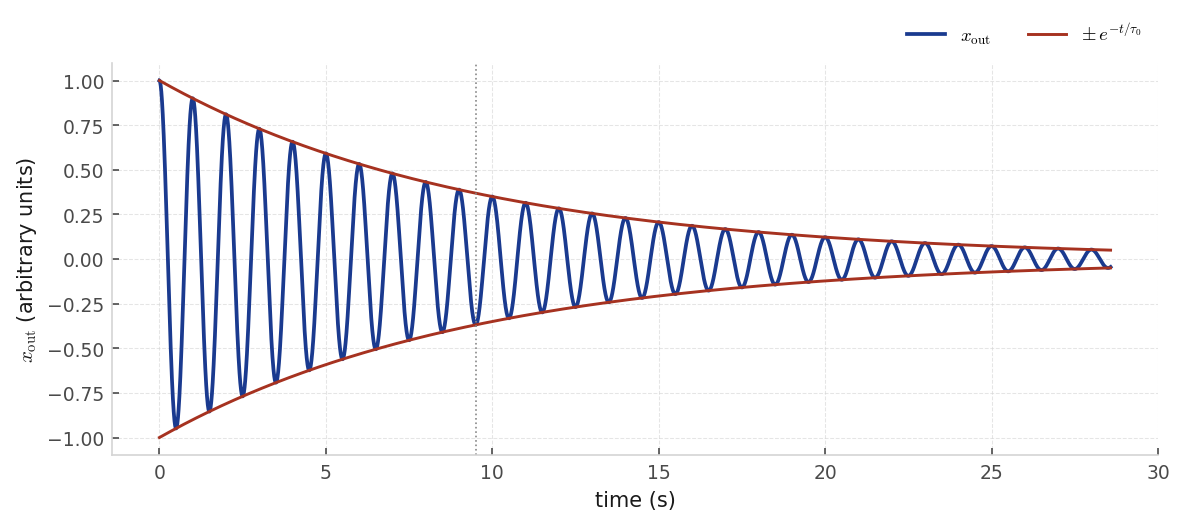

In [3]:
# change these: the oscillator of the laboratory
m = 1.0       # mass of the mirror (kg)
k = 39.5      # spring constant (N/m): f0 = sqrt(k/m) / 2 pi, 1 Hz here
b = 0.21      # damping coefficient (kg/s): Q = sqrt(k m) / b, 30 here

# the three numbers that describe it: natural frequency, quality factor, decay time
f0, Q, tau0 = oscillator_parameters(m, k, b)
print(f"f0 = {f0:.5f} Hz   Q = {Q:.2f}   tau0 = {tau0:.3f} s   swings in one decay time = {tau0 * f0:.2f}")

# let the mirror go from x = 1 with zero velocity and follow it for three decay times
t = np.linspace(0, 3 * tau0, 6001)
sol = solve_ivp(rhs, (0, t[-1]), [1.0, 0.0], t_eval=t, args=(m, k, b, ground_at_rest, ()),
                rtol=1e-10, atol=1e-12)
x_out = sol.y[0]

# the motion, and the envelope exp(-t/tau0) that it should follow; dotted: t = tau0
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(t, x_out, color=P['BLUE'], lw=1.8, label=r'$x_{\mathrm{out}}$')
ax.plot(t, np.exp(-t / tau0), color=P['BRICK'], lw=1.4, label=r'$\pm\,e^{-t/\tau_0}$')
ax.plot(t, -np.exp(-t / tau0), color=P['BRICK'], lw=1.4)
ax.axvline(tau0, color=P['GREY_MID'], lw=0.8, ls=':')
ax.set(xlabel='time (s)', ylabel=r'$x_{\mathrm{out}}$ (arbitrary units)')
ax.legend(loc='lower right', bbox_to_anchor=(1.0, 1.0), ncol=2, frameon=False)
plt.show()

## The routines

Every function of the laboratory is defined once, in the cell below. Read the docstring of each before you use it: it says what the function does, which units it takes and which units it returns. The first three are in the cell of the free oscillator.

| Routine | What it does | Tasks |
|---|---|---|
| `oscillator_parameters` | $f_{0}$, $Q$ and $\tau_{0}$ from $m$, $k$, $b$ | all |
| `ground_at_rest`, `cosine_drive`, `cosines_drive`, `sampled_drive` | the ground motion $x_{\mathrm{in}}(t)$: none, one cosine, two cosines, any samples | free oscillator, 1, 2 |
| `rhs` | Newton's second law of the mirror, in the form the solver wants | free oscillator, 1, 2 |
| `transfer` | the formula $G(f)$ | 1 to 8 |
| `steady_response` | integrates a cosine drive and measures amplitude, phase and mean power in the steady state | 1, 3 |
| `respond` | integrates the mirror for any ground motion | 2 |
| `apply_transfer` | the mirror as the product $G\,X_{\mathrm{in}}$ in frequency | 2 |
| `peak_numbers` | height, frequency and half-power width of a peak | 4, 5, 6 |
| `thermal_line` | the thermal motion $S(f)$ of a mode | 6 |
| `draw_regimes` | draws $|G|$ and its phase with the regimes marked | 7 |
| `stage` | $|G|$ of one pendulum of length $\ell$ | 8 |

The three numbers `N_DECAY`, `N_CYCLES` and `N_SAMPLES` fix how `steady_response` measures. They are constants and you do not change them.

In [4]:
# how steady_response measures (constants, not to be changed)
N_DECAY = 12      # wait 12 decay times: exp(-12) = 6e-6 of the free ringing is left, far below the tolerance of the tasks
N_CYCLES = 20     # analyse 20 whole cycles of the drive: enough to average out any small leftover
N_SAMPLES = 40    # samples per cycle: 40 resolve a cosine and a sine well
G_EARTH = 9.81    # acceleration of gravity (m/s^2), used by the pendulum of task 8


def transfer(f, m, k, b):
    """Return the transfer function G = X_out / X_in of the oscillator.

    Parameters
    ----------
    f       : float or array, frequency of the ground motion (Hz)
    m, k, b : mass (kg), spring constant (N/m), damping coefficient (kg/s)

    Returns
    -------
    G : complex, same shape as f, no unit; |G| is the amplitude, angle(G) the phase (rad)
    """
    # the formula of the text, with k = m w0^2 and b = m w0 / Q
    w = 2 * np.pi * f
    g = k / (k - m * w ** 2 + 1j * b * w)
    return g


def cosine_drive(t, f_drive):
    """Return the ground position x_in = cos(2 pi f_drive t), for t in s and f_drive in Hz (amplitude 1)."""
    x_in = np.cos(2 * np.pi * f_drive * t)
    return x_in


def cosines_drive(t, f1, amp1, f2, amp2):
    """Return the ground position x_in = amp1 cos(2 pi f1 t) + amp2 cos(2 pi f2 t); t in s, f1 and f2 in Hz."""
    x_in = amp1 * np.cos(2 * np.pi * f1 * t) + amp2 * np.cos(2 * np.pi * f2 * t)
    return x_in


def sampled_drive(t, times, values):
    """Return the ground position x_in at the time t (s), joining the samples (times, values) with straight lines."""
    x_in = np.interp(t, times, values)
    return x_in


def steady_response(m, k, b, f_drive):
    """Return the steady-state amplitude, phase and mean power of the mirror for the drive cos(2 pi f_drive t).

    The function integrates Newton's second law, waits for the transient to die and
    measures the motion that is left, which is at the frequency of the drive.

    Parameters
    ----------
    m, k, b : mass (kg), spring constant (N/m), damping coefficient (kg/s)
    f_drive : frequency of the ground motion (Hz)

    Returns
    -------
    (amplitude, phase_deg, power_mean) : amplitude of x_out for a ground amplitude of 1 (no unit),
        phase of x_out against the drive (degrees), mean power given to the mirror (W for a ground amplitude of 1 m)
    """
    f0, q, tau0 = oscillator_parameters(m, k, b)
    w = 2 * np.pi * f_drive

    # wait N_DECAY decay times, rounded up to a whole number of cycles of the drive
    t_start = np.ceil(N_DECAY * tau0 * f_drive) / f_drive
    # then record N_CYCLES whole cycles, N_SAMPLES samples in each
    t = t_start + np.arange(N_CYCLES * N_SAMPLES) / (N_SAMPLES * f_drive)

    # integrate from rest, with the cosine drive
    sol = solve_ivp(rhs, (0, t[-1]), [0.0, 0.0], t_eval=t, args=(m, k, b, cosine_drive, (f_drive,)),
                    rtol=1e-8, atol=1e-11)
    x_out, v = sol.y

    # project the motion on a cosine and a sine: their coefficients give the amplitude and the phase
    c = 2 * np.mean(x_out * np.cos(w * t))
    d = 2 * np.mean(x_out * np.sin(w * t))
    amplitude = np.hypot(c, d)
    phase_deg = np.degrees(np.arctan2(-d, c))

    # mean power: the force that the spring passes, k x_in, times the velocity
    power_mean = np.mean(k * cosine_drive(t, f_drive) * v)
    response = (amplitude, phase_deg, power_mean)
    return response


def respond(m, k, b, drive, drive_args, t):
    """Return the mirror position x_out on the times t (s), starting from rest.

    Parameters
    ----------
    m, k, b    : mass (kg), spring constant (N/m), damping coefficient (kg/s)
    drive      : function drive(t, *drive_args), the ground position x_in
    drive_args : tuple of the extra arguments of drive
    t          : array of the times (s), evenly spaced, starting at 0
    """
    # a step of the solver is never longer than the spacing of the times: a sampled drive is not missed
    sol = solve_ivp(rhs, (0, t[-1]), [0.0, 0.0], t_eval=t, args=(m, k, b, drive, drive_args),
                    rtol=1e-10, atol=1e-12, max_step=t[1] - t[0])
    x_out = sol.y[0]
    return x_out


def apply_transfer(m, k, b, x_in, fs):
    """Return the mirror position x_out as the product G X_in in frequency.

    Parameters
    ----------
    m, k, b : mass (kg), spring constant (N/m), damping coefficient (kg/s)
    x_in    : array, ground position sampled at the rate fs
    fs      : sampling rate (Hz)

    Returns
    -------
    x_out : array of the same length as x_in, in the unit of x_in
    """
    # add zeros after the ground motion, so that the ringing can die inside the transform
    n = 8 * x_in.size
    f = np.fft.rfftfreq(n, d=1 / fs)
    # multiply the spectrum of the input by G, go back to time and keep the original duration
    spectrum_out = transfer(f, m, k, b) * np.fft.rfft(x_in, n=n)
    x_out = np.fft.irfft(spectrum_out, n=n)[:x_in.size]
    return x_out


def peak_numbers(f, gain):
    """Return the height, the frequency and the full width at half power of the peak of gain.

    Parameters
    ----------
    f    : array, increasing frequencies (Hz)
    gain : array, an amplitude such as |G| on the frequencies f

    Returns
    -------
    (height, f_peak, width) : height in the unit of gain, f_peak and width in the unit of f
    """
    # the peak is the largest value of the gain
    i = np.argmax(gain)
    # half power is a fall of the amplitude by sqrt(2): the width runs from the first to the last frequency above it
    inside = f[gain >= gain[i] / np.sqrt(2)]
    numbers = (gain[i], f[i], inside[-1] - inside[0])
    return numbers


def thermal_line(f, m, k, b):
    """Return the thermal motion per hertz S(f) of a mode (arbitrary units).

    The thermal push has a level proportional to 1 / Q and the oscillator multiplies it by |G|^2.

    Parameters
    ----------
    f       : float or array, frequency (Hz)
    m, k, b : mass (kg), spring constant (N/m), damping coefficient (kg/s)
    """
    f0, q, tau0 = oscillator_parameters(m, k, b)
    s = np.abs(transfer(f, m, k, b)) ** 2 / q
    return s


def draw_regimes(m, k, b):
    """Draw |G| and its phase with f0, the resonance band and (f0/f)^2 marked; return f0 (Hz) and Q.

    Parameters
    ----------
    m, k, b : mass (kg), spring constant (N/m), damping coefficient (kg/s)
    """
    f0, q, tau0 = oscillator_parameters(m, k, b)
    # a log grid wide enough to hold the detector band and the resonance
    f = np.geomspace(min(0.01, f0 / 30), max(1000.0, 30 * f0), 20000)
    G = transfer(f, m, k, b)
    fig, (axa, axb) = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
    axa.loglog(f, np.abs(G), color=P['BLUE'], lw=1.6, label='$|G|$')
    # the asymptote (f0/f)^2, drawn only where it holds: above 3 f0
    above = f > 3 * f0
    axa.loglog(f[above], (f0 / f[above]) ** 2, color=P['BRICK'], lw=1.2, ls='--', label='$(f_0/f)^2$')
    # green: the detector band, 10 to 100 Hz; amber: the resonance band f0 +- f0/2Q; dotted: f0
    for ax, tag in ((axa, True), (axb, False)):
        ax.axvspan(10, 100, color=P['SAGE'], alpha=0.15, label='detector band' if tag else None)
        ax.axvspan(f0 * (1 - 1 / (2 * q)), f0 * (1 + 1 / (2 * q)), color=P['AMBER'], alpha=0.3,
                   label='resonance band' if tag else None)
        ax.axvline(f0, color=P['GREY_MID'], lw=0.8, ls=':')
    axa.set(ylabel='$|G|$ (no unit)')
    axa.legend(loc='lower right', bbox_to_anchor=(1.0, 1.0), ncol=4, frameon=False)
    axb.semilogx(f, np.angle(G, deg=True), color=P['BLUE'], lw=1.6)
    axb.set(xlabel='frequency of the ground motion (Hz)', ylabel='phase (degrees)', yticks=[-180, -90, 0])
    plt.show()
    params = (f0, q)
    return params


def stage(f, m, ell, phi_loss):
    """Return |G| (no unit) of one pendulum.

    Parameters
    ----------
    f        : float or array, frequency (Hz)
    m        : mass hanging from the pendulum (kg)
    ell      : length of the pendulum (m)
    phi_loss : loss angle of the fibre (no unit); it plays the role of 1 / Q
    """
    # the pendulum is an oscillator with spring constant m g / ell
    k = m * G_EARTH / ell
    # the loss angle fixes the friction: b = sqrt(k m) / Q
    b = np.sqrt(k * m) * phi_loss
    gain = np.abs(transfer(f, m, k, b))
    return gain

## Part A · How we find the transfer function

The ground moves and the mirror answers. How much of the ground motion reaches the mirror, at each frequency? The transfer function says it. We find it from the equation and then we check it against the motion itself.

### Task 1 · The transfer function from the equation, checked against the motion

The ground moves the support by $x_{\mathrm{in}}(t)$. The spring force depends on the stretch, $-k(x_{\mathrm{out}} - x_{\mathrm{in}})$. The friction acts on the motion of the mirror, $-b\,\dot{x}_{\mathrm{out}}$. Newton's second law adds them. We move the terms in $x_{\mathrm{out}}$ to the left and divide by $m$:

$$
\ddot{x}_{\mathrm{out}} + \frac{\omega_{0}}{Q}\,\dot{x}_{\mathrm{out}} + \omega_{0}^{2}\,x_{\mathrm{out}} = \omega_{0}^{2}\,x_{\mathrm{in}}(t) .
$$

We take the Fourier transform. Each time derivative becomes a factor $\mathrm{i}\omega$, so $\ddot{x}_{\mathrm{out}} \to -\omega^{2}X_{\mathrm{out}}$. Then we divide by $X_{\mathrm{in}}$:

$$
G(\omega) = \frac{X_{\mathrm{out}}}{X_{\mathrm{in}}}
= \frac{\omega_{0}^{2}}{\omega_{0}^{2} - \omega^{2} + \mathrm{i}\,\omega\omega_{0}/Q} .
$$

**What is the steady state?** When the ground starts to move as $x_{\mathrm{in}} = \cos 2\pi f t$, the motion of the mirror is the sum of two parts: its own free ringing (the transient), which dies in a few $\tau_{0}$ and the forced motion at the frequency of the drive. After the transient has died the mirror moves only at $f$, as $|G|\cos(2\pi f t + \phi)$, with $|G|$ the modulus and $\phi$ the phase of $G$. This is the steady state.

The code integrates Newton's second law for the cosine drive long enough for the transient to die, measures the amplitude and the phase of the mirror and compares them with $G$. It takes about half a minute at $Q = 30$.

**Routines used.** `oscillator_parameters`, `rhs`, `ground_at_rest`, `cosine_drive`, `transfer`, `steady_response`.

> **The symbols**
>
> - **$f$** — the frequency of the ground motion, in hertz; $\omega = 2\pi f$
> - **$X_{\mathrm{in}}(\omega)$, $X_{\mathrm{out}}(\omega)$** — the Fourier transforms of the input and of the output
> - **$G(\omega)$** — the transfer function: $|G|$ is the amplitude of the mirror for a ground amplitude of 1 and $\phi$ its phase
> - **$\bar{P}$** — the mean power the drive gives to the mirror, in watts; task 3 uses it

Q = 29.93   f0 = 1.00027 Hz
amplitude, integration against |G|: largest relative difference 2.4e-06
phase, integration against the phase of G: largest difference 5.2e-05 degrees


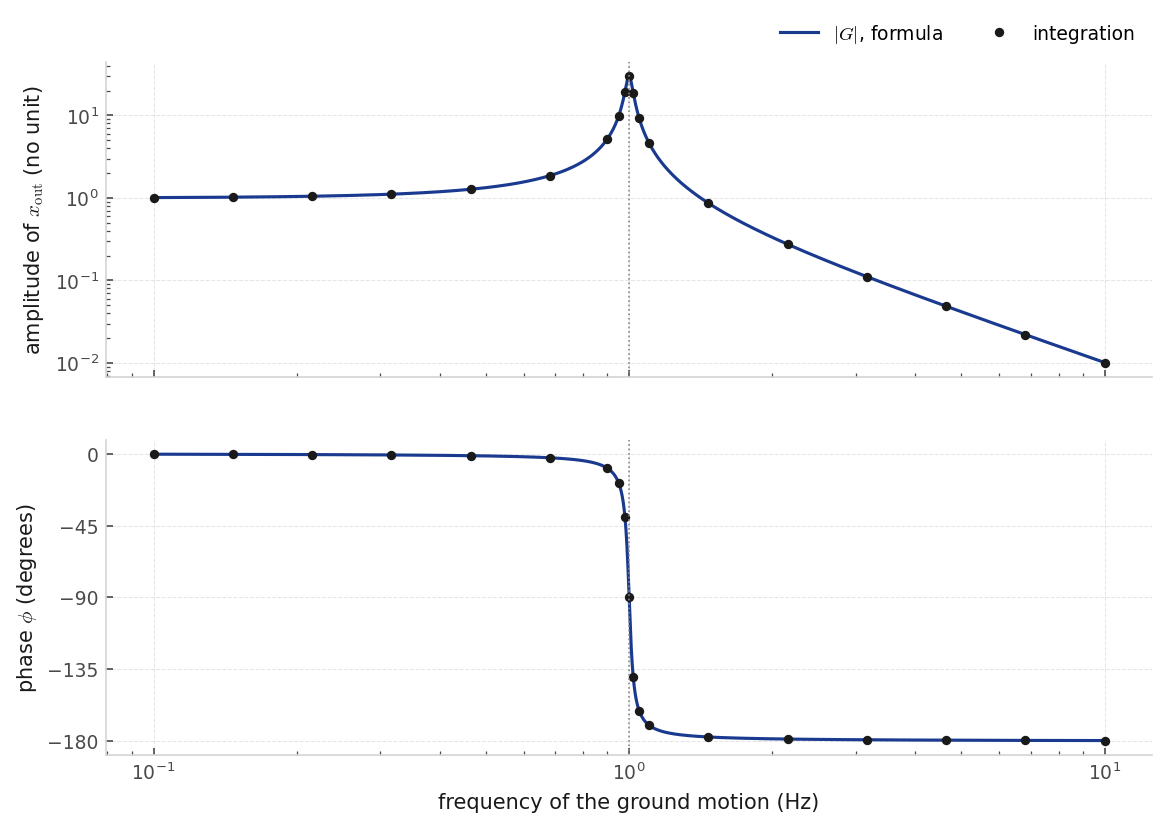

In [18]:
# change these: the oscillator
m = 1.0       # mass of the mirror (kg)
k = 39.5      # spring constant (N/m): f0 = sqrt(k/m) / 2 pi
b = 0.21      # damping coefficient (kg/s): Q = sqrt(k m) / b

f0, Q, tau0 = oscillator_parameters(m, k, b)

# the frequencies at which we integrate: a log grid from f0/10 to 10 f0, plus points near f0
f_sweep = f0 * np.unique(np.round(np.concatenate([np.geomspace(0.1, 10, 13),
                                                  [0.9, 0.95, 0.98, 1.02, 1.05, 1.1]]), 6))
# the steady-state amplitude and phase of the mirror at each of them (the power is not used here)
amplitude, phase_deg, power_mean = np.array([steady_response(m, k, b, f_i) for f_i in f_sweep]).T

# the formula G(f) on a fine grid, to draw as a line, and on the sweep, to compare
f_fine = f0 * np.geomspace(0.1, 10, 2000)
G = transfer(f_fine, m, k, b)
G_sweep = transfer(f_sweep, m, k, b)

# how far the integration is from the formula, in amplitude and in phase
print(f"Q = {Q:.2f}   f0 = {f0:.5f} Hz")
print(f"amplitude, integration against |G|: largest relative difference "
      f"{np.max(np.abs(amplitude / np.abs(G_sweep) - 1)):.1e}")
print(f"phase, integration against the phase of G: largest difference "
      f"{np.max(np.abs(phase_deg - np.angle(G_sweep, deg=True))):.1e} degrees")

# amplitude above, phase below: the formula as a line, the integration as dots; dotted: f0
fig, (axa, axb) = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
axa.loglog(f_fine, np.abs(G), color=P['BLUE'], lw=1.5, label='$|G|$, formula')
axa.loglog(f_sweep, amplitude, 'o', color=P['INK'], ms=3.5, label='integration')
axa.set(ylabel=r'amplitude of $x_{\mathrm{out}}$ (no unit)')
axa.legend(loc='lower right', bbox_to_anchor=(1.0, 1.0), ncol=2, frameon=False)
axb.semilogx(f_fine, np.angle(G, deg=True), color=P['BLUE'], lw=1.5)
axb.semilogx(f_sweep, phase_deg, 'o', color=P['INK'], ms=3.5)
axb.set(xlabel='frequency of the ground motion (Hz)', ylabel=r'phase $\phi$ (degrees)',
        yticks=[-180, -135, -90, -45, 0])
for ax in (axa, axb):
    ax.axvline(f0, color=P['GREY_MID'], lw=0.8, ls=':')
plt.show()

**What to change.** On the line `# change these`, one parameter at a time. Run the cell again each time:
1. Nothing first: read $|G|$ and $\phi$ at $f \ll f_{0}$, at $f_{0}$ and at $f \gg f_{0}$ from the formula, then compare with the plot.
2. `k` (try 20 and 80 N/m): where does the curve move?
3. `m` (try 0.5 and 2 kg): the same question.
4. `b` (try 0.05 and 1 kg/s): what happens to the peak?
In each case look at the printed differences: do the dots still lie on the line?

**What to look for.** The dots of the integration lie on the formula: $G$, found from the equation with one division, is what the mirror does. Three regimes. Well below $f_{0}$ the amplitude is 1 and the phase $0^{\circ}$: the mirror follows the ground. Near $f_{0}$ the amplitude grows and the phase passes $-90^{\circ}$. Well above $f_{0}$ the amplitude falls and the phase goes to $-180^{\circ}$.

**Question.** Before you run the cell, read from the formula $|G|$ and $\phi$ at $\omega \ll \omega_{0}$, at $\omega = \omega_{0}$ and at $\omega \gg \omega_{0}$. Then change $k$, then $m$, then $b$. Does the formula still describe the integration? Which two numbers fix the whole curve?

<details>
<summary>Solution</summary>

For $\omega \ll \omega_{0}$ the denominator is $\omega_{0}^{2}$ and $G = 1$: $|G| = 1$ and $\phi = 0^{\circ}$. At $\omega = \omega_{0}$ the real part of the denominator is zero and $G = \omega_{0}^{2}/(\mathrm{i}\,\omega_{0}^{2}/Q) = -\mathrm{i} Q$: $|G| = Q$ and $\phi = -90^{\circ}$. For $\omega \gg \omega_{0}$ the denominator is $-\omega^{2}$ and $G = -\omega_{0}^{2}/\omega^{2}$: $|G| = (\omega_{0}/\omega)^{2}$ and $\phi = -180^{\circ}$.

The integration agrees with the formula for every choice: the amplitude to about a few parts in $10^{6}$ and the phase to a few hundredths of a degree, the tolerance of the solver and of the projection. The equation is linear with constant coefficients, so the answer to a cosine is a cosine of the same frequency and $G$ is all we need to know.

The curve depends on two numbers only. The frequency axis is $f/f_{0}$ and the shape is fixed by $Q$. A stiffer spring or a lighter mass moves the whole curve along the frequency axis without changing its shape at fixed $Q$. Less friction raises the peak and does not move it.

</details>


## Part B · Any input

One transfer function, found once, answers every input. The next task uses it on two sinusoids and on a random ground motion.

### Task 2 · Any input: $X_{\mathrm{out}} = G\,X_{\mathrm{in}}$

An input that is not one cosine is a sum of cosines. The Fourier transform finds the sum. If the system is linear the output for a sum of inputs is the sum of the outputs. So in frequency the output is one product, $X_{\mathrm{out}} = G\,X_{\mathrm{in}}$, for any input.

The cell moves the ground with two sinusoids, separately and together. Then it moves it at random. It finds the motion of the mirror twice: by integrating the equation and by the product $G\,X_{\mathrm{in}}$.

**Routines used.** `respond`, `apply_transfer`, `cosines_drive`, `sampled_drive`, `transfer`.

In [6]:
# change these: the oscillator and the two sinusoids of the ground
m = 1.0       # mass of the mirror (kg)
k = 39.5      # spring constant (N/m)
b = 0.21      # damping coefficient (kg/s)
f1 = 0.7      # frequency of the first sinusoid (Hz)
f2 = 2.3      # frequency of the second sinusoid (Hz)
amp1 = 1.0    # amplitude of the first sinusoid (arbitrary units)
amp2 = 0.5    # amplitude of the second sinusoid (arbitrary units)

# twenty seconds of ground motion, sampled 200 times per second
FS = 200.0    # sampling rate (Hz)
t = np.arange(0, 20, 1 / FS)

# the mirror for the first sinusoid alone, the second alone and both together
x_out_a = respond(m, k, b, cosines_drive, (f1, amp1, f2, 0.0), t)
x_out_b = respond(m, k, b, cosines_drive, (f1, 0.0, f2, amp2), t)
x_out_ab = respond(m, k, b, cosines_drive, (f1, amp1, f2, amp2), t)
print(f"two sinusoids: largest |x_out,ab - x_out,a - x_out,b| = "
      f"{np.max(np.abs(x_out_ab - x_out_a - x_out_b)):.1e} on a signal of {np.max(np.abs(x_out_ab)):.2f}")

# a random ground: one Gaussian number of rms 1 every 5 ms
x_in_noise = np.random.default_rng(20150914).normal(0.0, 1.0, t.size)

# the mirror for the random ground, found by integrating the equation and by the product G X_in
x_out_ivp = respond(m, k, b, sampled_drive, (t, x_in_noise), t)
x_out_product = apply_transfer(m, k, b, x_in_noise, FS)
print(f"random ground: rms of x_out = {x_out_ivp.std():.3f}, largest difference of the"
      f" product / rms = {np.max(np.abs(x_out_product - x_out_ivp)) / x_out_ivp.std():.3f}")

two sinusoids: largest |x_out,ab - x_out,a - x_out,b| = 5.7e-11 on a signal of 3.58
random ground: rms of x_out = 0.652, largest difference of the product / rms = 0.024


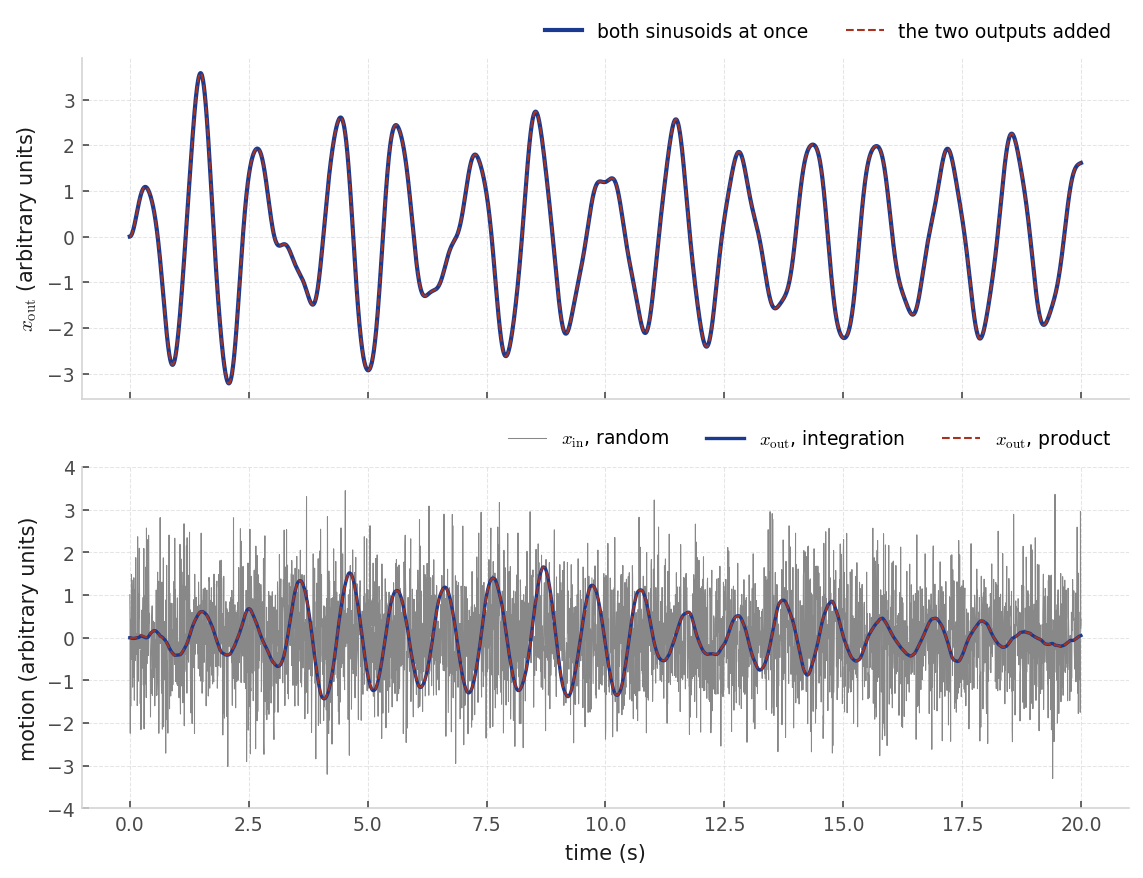

In [7]:
# above: both sinusoids at once against the sum of the two single outputs; below: the random ground
fig, (axa, axb) = plt.subplots(2, 1, figsize=(9, 6.5), sharex=True)
axa.plot(t, x_out_ab, color=P['BLUE'], lw=2.0, label='both sinusoids at once')
axa.plot(t, x_out_a + x_out_b, color=P['BRICK'], lw=1.0, ls='--', label='the two outputs added')
axa.set(ylabel=r'$x_{\mathrm{out}}$ (arbitrary units)')
axa.legend(loc='lower right', bbox_to_anchor=(1.0, 1.0), ncol=2, frameon=False)
axb.plot(t, x_in_noise, color=P['GREY_MID'], lw=0.5, label=r'$x_{\mathrm{in}}$, random')
axb.plot(t, x_out_ivp, color=P['BLUE'], lw=1.6, label=r'$x_{\mathrm{out}}$, integration')
axb.plot(t, x_out_product, color=P['BRICK'], lw=1.0, ls='--', label=r'$x_{\mathrm{out}}$, product')
axb.set(xlabel='time (s)', ylabel='motion (arbitrary units)', ylim=(-4, 4))
axb.legend(loc='lower right', bbox_to_anchor=(1.0, 1.0), ncol=3, frameon=False)
plt.show()

**What to change.** Run the cell as it is, then change on the line `# change these`:
1. `b` (try 0.02 and 2 kg/s): how does the ringing of the mirror in the lower plot change?
2. `k` (try 10 and 160 N/m): where does the mirror swing now?
Look at the printed difference between the sum of the two outputs and the output of the sum.

**What to look for.** The answer to the sum is the sum of the answers. For the random ground the product gives the integration with no loop in time. The mirror does not follow the fast jitter of the ground: it rings near $f_{0}$ and smooths the rest.

**Question.** Which term in the equation of the mirror would break the superposition and what would the output then contain? Why does the random ground make the mirror swing mostly near $f_{0}$?

<details>
<summary>Solution</summary>

The two sinusoids add to about $10^{-9}$, the tolerance of the solver. For the random ground the product agrees with the integration to about $0.02$ of the rms. The integration joins the samples with straight lines and the product treats them as steps. The two pictures of the same ground differ inside each step.

A term that is not linear in $x_{\mathrm{out}}$ breaks it: a spring that stiffens, with a force $-k x_{\mathrm{out}} - \kappa x_{\mathrm{out}}^{3}$. The output for the sum would contain frequencies that neither input carries, such as $3\times0.7$ Hz and $2\times0.7 + 2.3$ Hz and the difference would grow with the amplitude. The random ground moves at every frequency with the same strength. The mirror multiplies each frequency by $|G|$: $Q$ times near $f_{0}$, 1 below, $(f_{0}/f)^{2}$ above. So the output is a ringing near $f_{0}$ with a slowly changing amplitude.

</details>


## Part C · The resonance

Near the natural frequency $f_{0}$ the mirror moves much more than the ground: this is the **resonance**. In task 3 we find where it is and why. In task 4 we see that the quality factor $Q$ sets how high and how narrow the peak is.


### Task 3 · What a resonance is: amplitude, phase and power

A resonance is the frequency where the drive gives the mirror the most. At the natural frequency $f_{0}$ the phase is $-90^{\circ}$, $|G| = Q$ and the drive gives the most power. The peak of $|G|$ lies just below, at

$$
f_{r} = f_{0}\sqrt{1 - \frac{1}{2Q^{2}}} .
$$

The cell sweeps $f$ from $f_{0}/10$ to $10f_{0}$ and draws the steady-state amplitude, phase and mean power as dots on the formulas. For a ground amplitude of 1 the power is $\bar{P} = -\tfrac{1}{2}\,k\,\omega\,\mathrm{Im}\,G$. It takes about a minute at $Q = 30$.

**Routines used.** `oscillator_parameters`, `transfer`, `steady_response`.

> **The symbols**
>
> - **$f_{r}$** — the frequency of the peak of $|G|$
> - **$\mathrm{Im}\,G$** — the imaginary part of $G$

Q = 29.93   f0 = 1.00027 Hz   f_r = 0.99999 Hz
largest amplitude 29.932 at 1.00000 Hz
largest power at 1.00027 Hz, phase -90 deg at 1.00027 Hz
integration against |G|: largest relative difference 2.4e-06


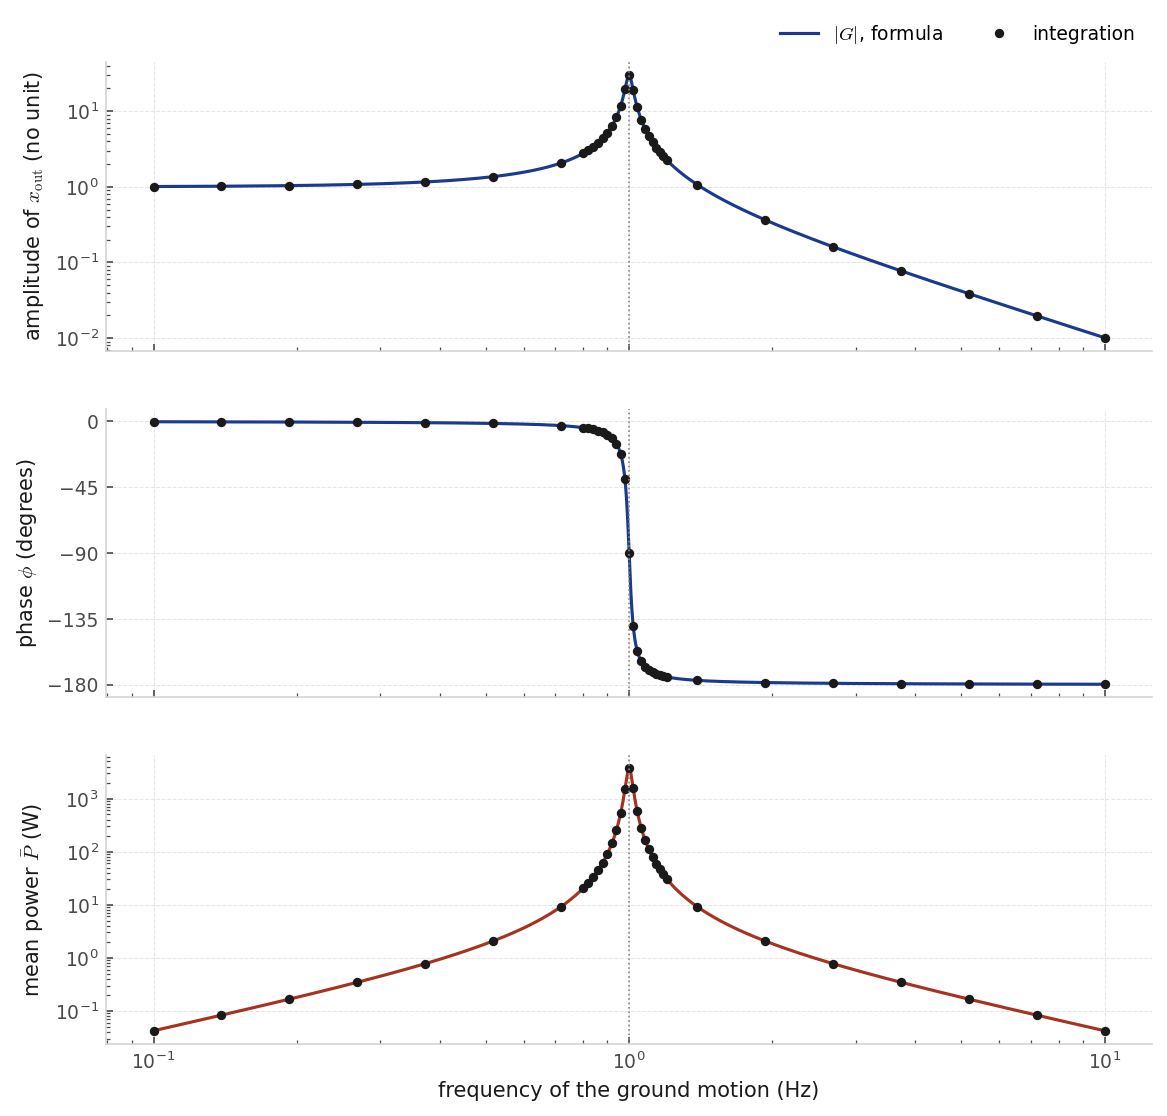

In [8]:
# change these: the oscillator
m = 1.0       # mass of the mirror (kg)
k = 39.5      # spring constant (N/m): f0 = sqrt(k/m) / 2 pi
b = 0.21      # damping coefficient (kg/s): Q = sqrt(k m) / b; one sweep takes about a minute at Q = 30

f0, Q, tau0 = oscillator_parameters(m, k, b)

# the frequencies at which we integrate: a log grid from f0/10 to 10 f0, plus 21 points from 0.8 f0 to 1.2 f0
f_sweep = f0 * np.unique(np.round(np.concatenate([np.geomspace(0.1, 10, 15),
                                                  np.linspace(0.8, 1.2, 21)]), 6))
# steady-state amplitude, phase and mean power of the mirror at each of them
amplitude, phase_deg, power_mean = np.array([steady_response(m, k, b, f_i) for f_i in f_sweep]).T

# the formulas on a very fine grid, to draw as lines and to find the peaks
f_fine = f0 * np.geomspace(0.1, 10, 400001)
G = transfer(f_fine, m, k, b)
power_formula = -0.5 * k * 2 * np.pi * f_fine * G.imag       # mean power for a ground amplitude of 1

# where the amplitude, the power and the phase of -90 degrees fall
print(f"Q = {Q:.2f}   f0 = {f0:.5f} Hz   f_r = {f0 * np.sqrt(1 - 1 / (2 * Q ** 2)):.5f} Hz")
print(f"largest amplitude {np.abs(G).max():.3f} at {f_fine[np.argmax(np.abs(G))]:.5f} Hz")
print(f"largest power at {f_fine[np.argmax(power_formula)]:.5f} Hz,"
      f" phase -90 deg at {f_fine[np.argmin(np.abs(np.angle(G, deg=True) + 90))]:.5f} Hz")
# how far the integrated amplitude is from the formula
mismatch = np.max(np.abs(amplitude / np.abs(transfer(f_sweep, m, k, b)) - 1))
print(f"integration against |G|: largest relative difference {mismatch:.1e}")

# amplitude, phase and power: the formulas as lines, the integration as dots; dotted: f0
fig, (axa, axb, axc) = plt.subplots(3, 1, figsize=(9, 8.5), sharex=True)
axa.loglog(f_fine, np.abs(G), color=P['BLUE'], lw=1.5, label='$|G|$, formula')
axa.loglog(f_sweep, amplitude, 'o', color=P['INK'], ms=3.5, label='integration')
axa.set(ylabel=r'amplitude of $x_{\mathrm{out}}$ (no unit)')
axa.legend(loc='lower right', bbox_to_anchor=(1.0, 1.0), ncol=2, frameon=False)
axb.semilogx(f_fine, np.angle(G, deg=True), color=P['BLUE'], lw=1.5)
axb.semilogx(f_sweep, phase_deg, 'o', color=P['INK'], ms=3.5)
axb.set(ylabel=r'phase $\phi$ (degrees)', yticks=[-180, -135, -90, -45, 0])
axc.loglog(f_fine, power_formula, color=P['BRICK'], lw=1.5)
axc.loglog(f_sweep, power_mean, 'o', color=P['INK'], ms=3.5)
axc.set(xlabel='frequency of the ground motion (Hz)', ylabel=r'mean power $\bar{P}$ (W)')
for ax in (axa, axb, axc):
    ax.axvline(f0, color=P['GREY_MID'], lw=0.8, ls=':')
plt.show()

**What to change.** On the line `# change these`:
1. `b` = 2.1 kg/s, then 6 kg/s: read the three printed frequencies.
2. `k` (try 20 and 80 N/m) with `b` = 0.21: do the three frequencies keep their order?
Compare the largest amplitude, the largest power and the phase of $-90^{\circ}$.

**What to look for.** The dots of the integration lie on the formula for the amplitude, the phase and the power. The power has one peak and it is narrow. The amplitude peaks a little lower in frequency.

**Question.** Raise $b$ to $2.1$ and then to $6$ kg/s. Where are the largest amplitude, the largest power and the phase of $-90^{\circ}$? Why does the drive give the most power exactly at $f_{0}$?

<details>
<summary>Solution</summary>

At $Q = 29.9$ the largest amplitude is $29.93$ at $f_{r} = 0.99999$ Hz. The largest power and the phase of $-90°$ are both at $f_{0} = 1.00027$ Hz, three parts in $10^{4}$ higher. The integration agrees with the formulas to the tolerance of the solver. At $b = 2.1$ kg/s ($Q = 3.0$) the peak is lower, $3.04$, much wider and at $f_{r} = 0.972f_{0}$; the power and the phase still mark $f_{0}$. At $b = 6$ kg/s ($Q = 1.05$) the peak is $1.19$ high at $0.74f_{0}$ and is barely a peak. Below $Q = 1/\sqrt{2}$ there is none.

At $f_{0}$ the phase is $-90°$: when the ground moves as a cosine, the mirror moves as a sine and its velocity as a cosine. The velocity is **in phase with the force** of the spring. The drive pushes the mirror the way it already moves in every part of every cycle, so it gives the most power. At $f_{0}$ the spring and the inertia cancel, $k = m\omega_{0}^{2}$ and $G(\omega_{0}) = k/(\mathrm{i} b\omega_{0}) = -\mathrm{i} Q$: only the friction limits the motion. The amplitude peaks a little lower, because at a lower frequency the same velocity is a larger displacement. For a high $Q$ the three frequencies merge into one number, the resonance.

</details>


### Task 4 · The height and the width of the resonance: the same $Q$ in frequency and in time

Lecture 8 says the height of the peak is $Q$ and its full width at half power, where $|G|$ is the peak divided by $\sqrt{2}$, is $\Delta\omega \simeq \omega_{0}/Q$ for $Q \gg 1$. The free oscillator decays in $\tau_{0} = 2Q/\omega_{0}$. So

$$
\tau_{0}\,\Delta\omega = \frac{2Q}{\omega_{0}}\,\frac{\omega_{0}}{Q} = 2 .
$$

The cell draws $|G|$ around $f_{0}$ for three values of $b$. For each it prints the height next to $Q$, the width next to $f_{0}/Q$ and $\tau_{0}\Delta\omega$.

**Routines used.** `oscillator_parameters`, `transfer`, `peak_numbers`.

> **The symbols**
>
> - **$\Delta f$** — the full width at half power of the peak, in hertz; $\Delta\omega = 2\pi\Delta f$

b =  2.10 kg/s: Q =   2.99   height   3.04   width 0.3446 Hz (f0/Q = 0.3342 Hz)   tau0 dw = 2.062
b =  0.63 kg/s: Q =   9.98   height   9.99   width 0.1005 Hz (f0/Q = 0.1003 Hz)   tau0 dw = 2.005
b =  0.21 kg/s: Q =  29.93   height  29.93   width 0.0334 Hz (f0/Q = 0.0334 Hz)   tau0 dw = 2.000


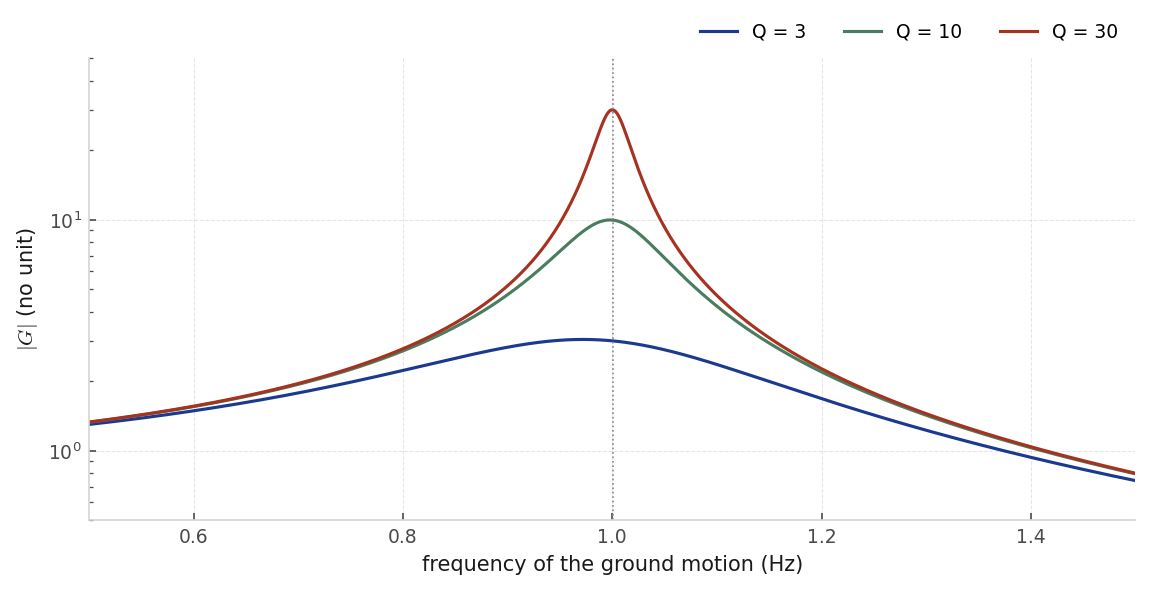

In [10]:
# change these: the oscillator, with three values of the damping
m = 1.0                       # mass of the mirror (kg)
k = 39.5                      # spring constant (N/m): f0 = sqrt(k/m) / 2 pi
b_values = (2.1, 0.63, 0.21)  # three damping coefficients (kg/s): Q = 3, 10, 30

# a fine frequency grid, so that the width is read to a fraction of a percent
f = np.linspace(0.01, 3.0, 600001)
fig, ax = plt.subplots(figsize=(9, 4))
for b, colour in zip(b_values, (P['BLUE'], P['SAGE'], P['BRICK'])):
    # Q and tau0 from the parameters, height and width from the curve |G|
    f0, Q, tau0 = oscillator_parameters(m, k, b)
    gain = np.abs(transfer(f, m, k, b))
    height, f_peak, width = peak_numbers(f, gain)
    print(f"b = {b:5.2f} kg/s: Q = {Q:6.2f}   height {height:6.2f}   width {width:.4f} Hz"
          f" (f0/Q = {f0 / Q:.4f} Hz)   tau0 dw = {tau0 * 2 * np.pi * width:.3f}")
    ax.plot(f, gain, color=colour, lw=1.5, label=f'Q = {Q:.0f}')
ax.axvline(f0, color=P['GREY_MID'], lw=0.8, ls=':')       # dotted: f0
ax.set(xlabel='frequency of the ground motion (Hz)', ylabel='$|G|$ (no unit)',
       xlim=(0.5, 1.5), ylim=(0.5, 50), yscale='log')
ax.legend(loc='lower right', bbox_to_anchor=(1.0, 1.0), ncol=3, frameon=False)
plt.show()

**What to change.** On the line `# change these`:
1. `m` (try 0.5 and 2 kg): which printed number moves?
2. `k` (try 20 and 80 N/m): the same question.
3. The three values of `b_values`: look at $\tau_{0}\Delta\omega$ for each.

**What to look for.** The higher $Q$, the taller and the narrower the peak. The width is close to $f_{0}/Q$ and $\tau_{0}\Delta\omega$ is close to 2.

**Question.** Change $m$ and then $k$. Which parameter moves the peak, which changes its height and which its width? Why is $\tau_{0}\Delta\omega = 2$ for every $b$ and why only roughly at $Q = 3$?

<details>
<summary>Solution</summary>

For $Q = 3.0$, $10.0$ and $29.9$ the height is $3.04$, $9.99$ and $29.93$, a little above $Q$. The width is $0.345$, $0.1005$ and $0.0334$ Hz against $f_{0}/Q = 0.334$, $0.1003$ and $0.0334$ Hz and $\tau_{0}\Delta\omega$ is $2.06$, $2.005$ and $2.000$.

The peak sits at $f_{0} = \sqrt{k/m}/2\pi$: a stiffer spring moves it up, a heavier mass down. The width is $\Delta\omega = \omega_{0}/Q = b/m$: friction over mass, nothing else. The height $Q = \sqrt{km}/b$ grows with both. The decay time $\tau_{0} = 2m/b$ is set by the same ratio, so $\tau_{0}\Delta\omega = 2$ for every $b$: a narrow peak and a long ringing are one fact, seen in frequency and in time. The width $\omega_{0}/Q$ holds for a narrow, symmetric peak, $Q \gg 1$. At $Q = 3$ the peak is a third of $f_{0}$ wide and the result is rough.

</details>


## Part D · At the resonance and away from it

A setup is built by choosing $m$, $k$ and $b$ and so $f_{0}$ and $Q$, for the job. Below $f_{0}$ the mirror follows the input. At $f_{0}$ it amplifies the input by $Q$, in a band $f_{0}/Q$ wide. Far above $f_{0}$ it isolates: $|G| \simeq (f_{0}/f)^{2}$. Tasks 5 and 6 work at the resonance: a resonant bar and a violin mode. Task 7 works away from it: the mass follows far below and isolates far above.

### Task 5 · A resonant bar: working at the resonance

The first gravitational-wave detectors were resonant bars: metal cylinders of a few tonnes that ring when a wave passes (Allen and others 2000). A bar must answer a weak force as strongly as it can, so it works at its resonance, near a kilohertz, with a high $Q$. The cell takes round numbers for this task: $m = 1000$ kg, $f_{0}$ near 900 Hz and $Q$ near $10^{6}$.

The cell prints $f_{0}$, $Q$, the height and the width of the peak, $|G|$ away from the peak, the decay time and $\tau_{0}\Delta\omega$. It draws the peak and the envelope of the ringing.

**Routines used.** `oscillator_parameters`, `transfer`, `peak_numbers`.

f0 = 900.32 Hz   Q = 2.095e+06   height of the peak 2.095e+06
width = 0.430 mHz   f0/Q = 0.430 mHz
   0.01 Hz above f0: |G| / height = 2.1e-02
   1.00 Hz above f0: |G| / height = 2.1e-04
 100.00 Hz above f0: |G| / height = 2.0e-06
tau0 = 741 s = 6.67e+05 swings   tau0 dw = 1.999


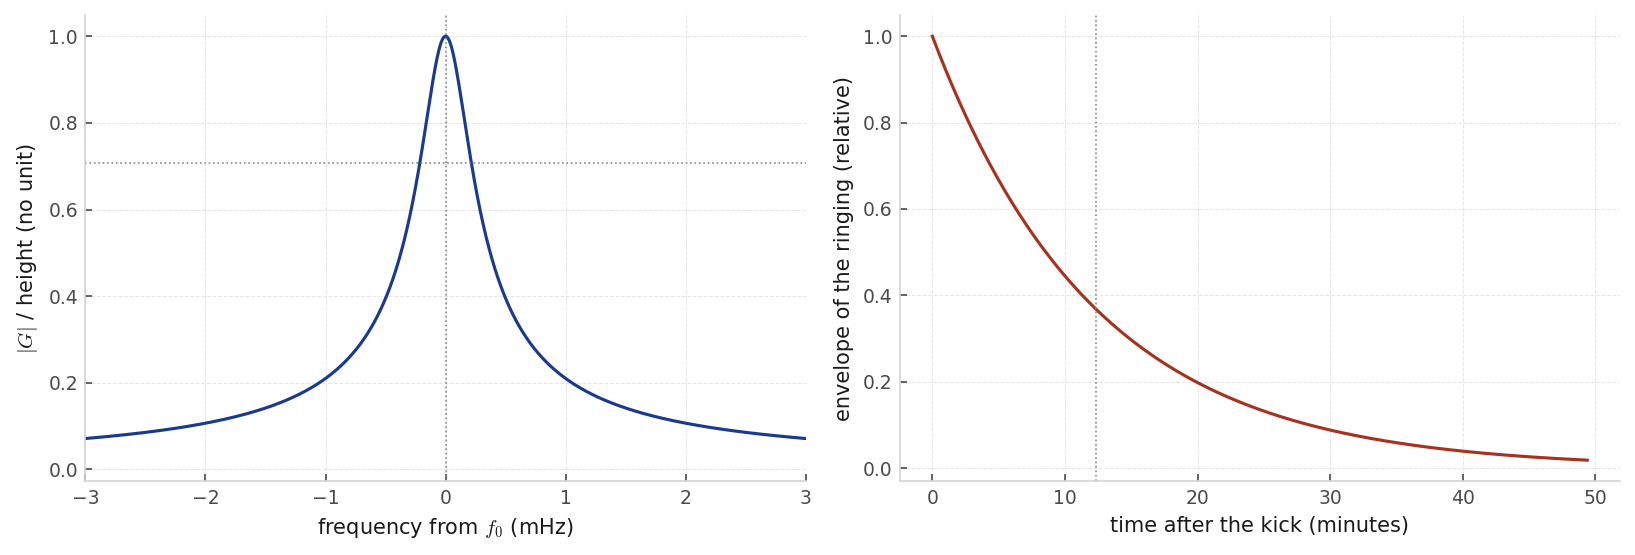

In [15]:
# change these: the bar
m = 1000.0    # mass of the bar (kg)
k = 3.2e10    # spring constant (N/m): f0 = sqrt(k/m) / 2 pi, near 900 Hz
b = 2.7       # damping coefficient (kg/s): Q = sqrt(k m) / b, near 1e6

f0, Q, tau0 = oscillator_parameters(m, k, b)

# the peak is less than a millihertz wide: look at +-10 mHz around f0 on a fine grid
offset = np.linspace(-0.01, 0.01, 200001)                 # frequency from f0 (Hz)
gain = np.abs(transfer(f0 + offset, m, k, b))
height, f_peak, width = peak_numbers(offset, gain)
print(f"f0 = {f0:.2f} Hz   Q = {Q:.3e}   height of the peak {height:.3e}")
print(f"width = {width * 1000:.3f} mHz   f0/Q = {f0 / Q * 1000:.3f} mHz")
# the response away from the peak, relative to its height
for far in (0.01, 1.0, 100.0):
    print(f"{far:7.2f} Hz above f0: |G| / height = {abs(transfer(f0 + far, m, k, b)) / height:.1e}")
# the price of the narrow band: a long ringing
print(f"tau0 = {tau0:.0f} s = {tau0 * f0:.2e} swings   tau0 dw = {tau0 * 2 * np.pi * width:.3f}")

# left: the peak, in units of its height, with the half-power level dotted; right: the envelope of the ringing
fig, (axa, axb) = plt.subplots(1, 2, figsize=(11, 3.8))
axa.plot(offset * 1000, gain / height, color=P['BLUE'], lw=1.5)
axa.axhline(1 / np.sqrt(2), color=P['GREY_MID'], lw=0.8, ls=':')
axa.axvline(0, color=P['GREY_MID'], lw=0.8, ls=':')       # f0 is at zero offset
axa.set(xlabel='frequency from $f_0$ (mHz)', ylabel='$|G|$ / height (no unit)', xlim=(-3, 3))
t_ring = np.linspace(0, 4 * tau0, 400)
axb.plot(t_ring / 60, np.exp(-t_ring / tau0), color=P['BRICK'], lw=1.5)
axb.axvline(tau0 / 60, color=P['GREY_MID'], lw=0.8, ls=':')   # dotted: t = tau0
axb.set(xlabel='time after the kick (minutes)', ylabel='envelope of the ringing (relative)')
plt.tight_layout()
plt.show()

**What to change.** On the line `# change these`:
1. `b` = 57 kg/s, then 0.57 kg/s: read the height, the width and the decay time.
2. `m` and `k` together, to keep $f_{0}$ near 900 Hz while $Q$ changes.

**What to look for.** The response at the peak is $Q$ times the response at low frequency, but only in a band $f_{0}/Q$ wide, less than one millihertz. One hertz away it is thousands of times smaller. So a bar hears one narrow band. The price is time: it rings for minutes after a kick.

**Question.** Make $b$ ten times larger, then ten times smaller. What happens to the gain, to the band the bar hears and to the time it rings? Can a bar have a wide band and a short ringing with the same gain?

<details>
<summary>Solution</summary>

With $m = 1000$ kg, $k = 3.2\times10^{10}$ N/m and $b = 5.7$ kg/s, $f_{0} = 900.3$ Hz and $Q = 9.9\times10^{5}$. The width is $0.91$ mHz, which is $f_{0}/Q$ and one hertz above the peak $|G|$ is $4.5\times10^{-4}$ of the height. The bar rings for $\tau_{0} = 351$ s, about $3\times10^{5}$ swings and $\tau_{0}\Delta\omega = 2.00$.

Ten times more friction makes the gain ten times smaller, the band ten times wider and the ringing ten times shorter; ten times less friction does the opposite. The gain $Q$, the band $f_{0}/Q$ and the ringing $2Q/\omega_{0}$ are tied together. A high gain comes only with a narrow band and a long ringing. That is what working at the resonance means: amplification, in a narrow band, paid for in time. A bar hears a signal that lies in its band and lasts long enough to fill it.

</details>


### Task 6 · A violin mode: a high $Q$ keeps the noise in a narrow line

A mirror hangs from fibres. A fibre rings like a string. Its violin modes are narrow lines in the data, a fundamental near 430 Hz in Advanced Virgo and harmonics above it. Each mode is an oscillator pushed at random by the heat of the fibre, with the same strength at every frequency and a level proportional to the loss $1/Q$ (Saulson 2017). The mirror then moves at each frequency with the strength of the push times $|G|^{2}$:

$$
S(f) \propto \frac{1}{Q}\,\left|G(f)\right|^{2} .
$$

The cell draws $S$ for a low $Q$ and a high $Q$ with round numbers. It prints the height of each line, its width and its area: the total motion of the mode.

**Routines used.** `thermal_line`, `oscillator_parameters`, `transfer`, `peak_numbers`.

> **The symbols**
>
> - **$S(f)$** — the strength of the motion of the mode at each frequency, per hertz, in arbitrary units

Q =     20: height    20.02   width 25.002 Hz (f0/Q = 24.987 Hz)   area 783.90   at 300 Hz 1.22e-01
Q =   2001: height  2001.05   width  0.250 Hz (f0/Q = 0.250 Hz)   area 785.40   at 300 Hz 1.22e-03


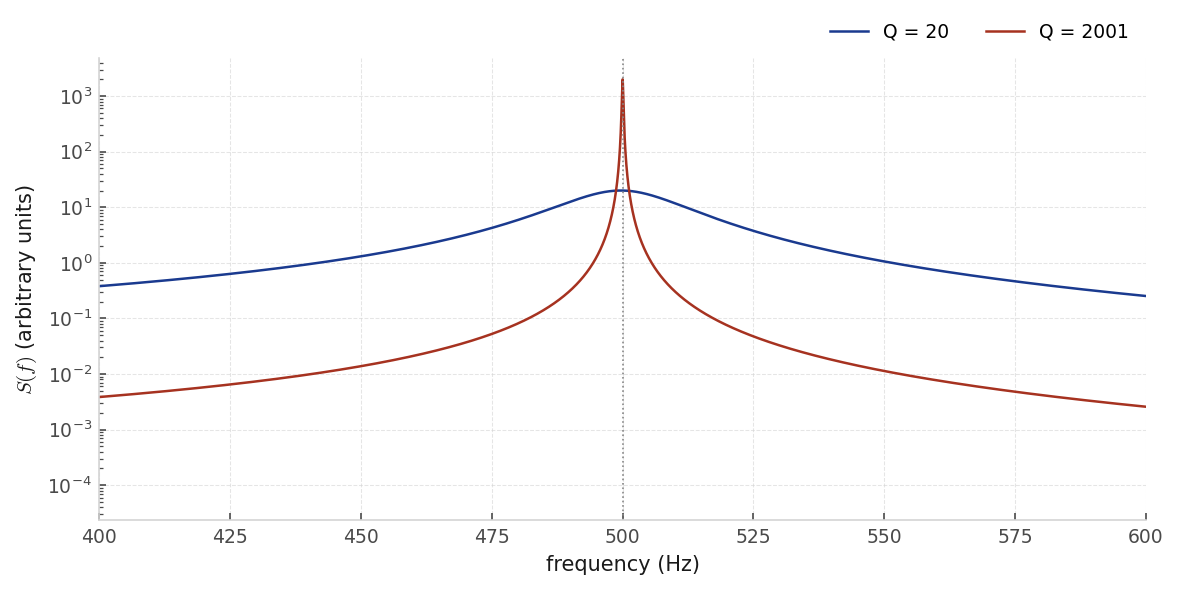

In [16]:
# change these: the mode, with two values of the damping
m = 1.0                    # effective mass of the mode (kg)
k = 9.87e6                 # spring constant (N/m): f0 = sqrt(k/m) / 2 pi, 500 Hz
b_values = (157.0, 1.57)   # two damping coefficients (kg/s): a low Q (20) and a high Q (2000)

# a grid fine enough to resolve a line a fraction of a hertz wide
f = np.linspace(1.0, 1000.0, 2000001)
fig, ax = plt.subplots(figsize=(9, 4))
for b, colour in zip(b_values, (P['BLUE'], P['BRICK'])):
    f0, Q, tau0 = oscillator_parameters(m, k, b)
    S = thermal_line(f, m, k, b)
    # the height and the width of the line (the peak of sqrt(S), whose half-power points are those of S) and its area
    height, f_peak, width = peak_numbers(f, np.sqrt(S))
    area = np.trapezoid(S, f)
    print(f"Q = {Q:6.0f}: height {height ** 2:8.2f}   width {width:6.3f} Hz (f0/Q = {f0 / Q:.3f} Hz)"
          f"   area {area:.2f}   at 300 Hz {thermal_line(300.0, m, k, b):.2e}")
    ax.semilogy(f, S, color=colour, lw=1.2, label=f'Q = {Q:.0f}')
ax.axvline(f0, color=P['GREY_MID'], lw=0.8, ls=':')       # dotted: f0
ax.set(xlabel='frequency (Hz)', ylabel='$S(f)$ (arbitrary units)', xlim=(400, 600))
ax.legend(loc='lower right', bbox_to_anchor=(1.0, 1.0), ncol=2, frameon=False)
plt.show()

**What to change.** On the line `# change these`:
1. The second value of `b_values`: 1.57, then 15.7 kg/s. Read the height, the width and the area.
2. `k` (try 4e6 and 2e7 N/m): where does the line move?

**What to look for.** The line of the high-$Q$ mode is a hundred times higher and a hundred times narrower than the line of the low-$Q$ mode. The area is the same. Far from the line the high-$Q$ mode is a hundred times quieter.

**Question.** Change the second $b$ from $1.57$ to $15.7$ kg/s. What happens to the height, the width and the area of the line? Why does the area not change and why do we want fibres with a high $Q$?

<details>
<summary>Solution</summary>

For $Q = 20$ the line is 20 high and 25 Hz wide; for $Q = 2001$ it is 2001 high and $0.25$ Hz wide. The area is $784$ and $785$, the same to the step of the frequency grid: $\pi f_{0}/2$ in these units. At 300 Hz the high-$Q$ mode is a hundred times lower. With $b = 15.7$ kg/s ($Q = 200$) the line is ten times lower and ten times wider than at $Q = 2000$ and the area is again the same.

The push grows with the loss, $1/Q$. The peak of $|G|^{2}$ grows as $Q^{2}$ over a width $f_{0}/Q$, so its area grows as $Q$. The two cancel: the total motion of the mode does not depend on $Q$. It is the energy of the mode in thermal equilibrium, set by the temperature. A high $Q$ squeezes that motion into a narrow line and leaves the rest of the band quieter. So fibres with a high $Q$ keep their thermal noise in lines a fraction of a hertz wide, which the analysis can remove and the detector is quiet between them.

</details>


### Task 7 · Away from the resonance: the mass follows below and isolates above

Far below $f_{0}$ the mirror follows the ground: $|G| \simeq 1$ and $\phi \simeq 0^{\circ}$. Far above $f_{0}$ it stays behind: $|G| \simeq (f_{0}/f)^{2}$ and $\phi \simeq -180^{\circ}$. A ground-based detector measures between 10 and 100 Hz, so we want that band far above the resonance of the mirror.

The cell draws $|G|$ and its phase. It marks $f_{0}$, the resonance band $f_{0} \pm f_{0}/2Q$ and the line $(f_{0}/f)^{2}$ and shades the band from 10 to 100 Hz. It prints $|G|$ and the phase at $f_{0}/100$ and at 10 and 100 Hz.

**Routines used.** `draw_regimes`, `oscillator_parameters`, `transfer`.

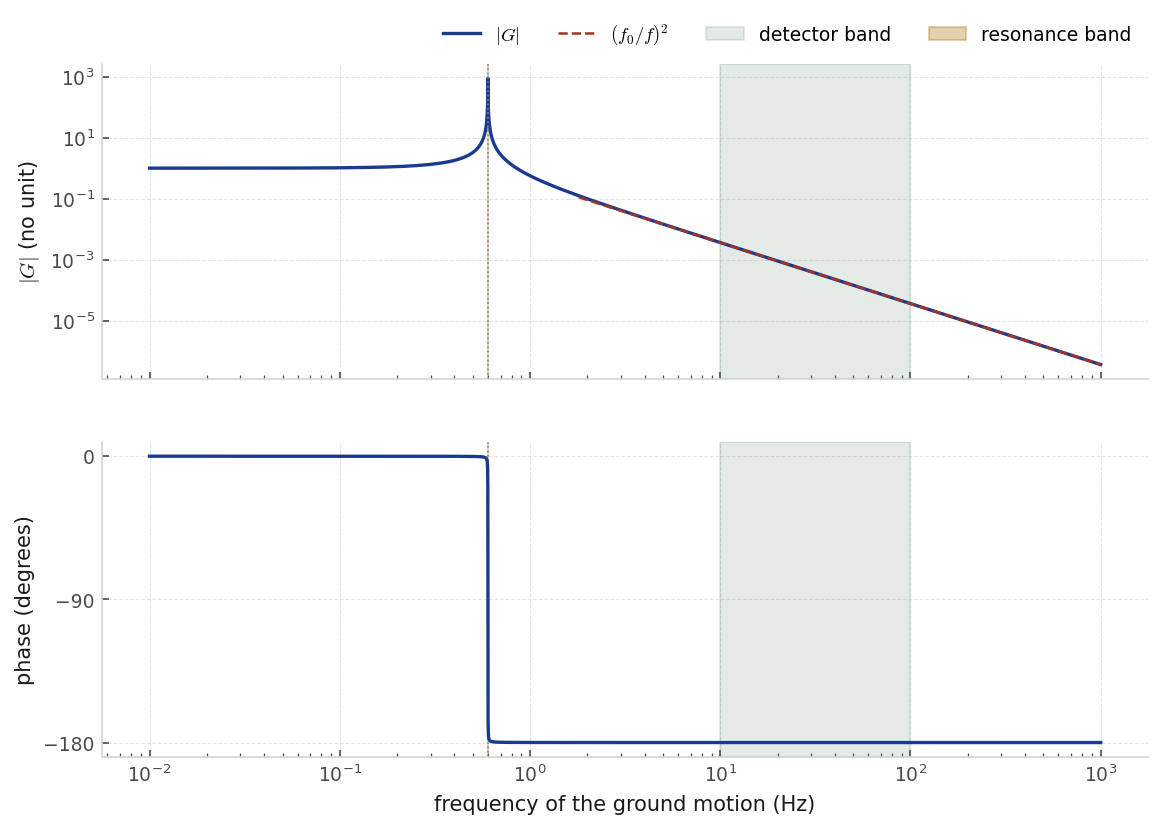

f0 = 0.601 Hz   Q = 1007   band of the resonance 0.60 mHz
f =    0.006 Hz: |G| = 1.00e+00   phase =   -0.00 deg
f =   10.000 Hz: |G| = 3.62e-03   phase = -180.00 deg
f =  100.000 Hz: |G| = 3.61e-05   phase = -180.00 deg
(f0/f)^2 at    10 Hz = 3.61e-03
(f0/f)^2 at   100 Hz = 3.61e-05


In [19]:
# change these: the suspended mirror
m = 40.0      # mass of the mirror (kg)
k = 570.0     # spring constant (N/m): f0 = sqrt(k/m) / 2 pi, 0.6 Hz
b = 0.15      # damping coefficient (kg/s): Q = sqrt(k m) / b, about 1000

# the drawing, and f0 and Q for the numbers below
f0, Q = draw_regimes(m, k, b)
print(f"f0 = {f0:.3f} Hz   Q = {Q:.0f}   band of the resonance {f0 / Q * 1000:.2f} mHz")
# |G| and the phase far below the resonance and at the two ends of the detector band
for f_i in (f0 / 100, 10.0, 100.0):
    g_i = transfer(f_i, m, k, b)
    print(f"f = {f_i:8.3f} Hz: |G| = {abs(g_i):.2e}   phase = {np.angle(g_i, deg=True):7.2f} deg")
# the asymptote (f0/f)^2 to compare with |G| in the detector band
for f_i in (10.0, 100.0):
    print(f"(f0/f)^2 at {f_i:5.0f} Hz = {(f0 / f_i) ** 2:.2e}")

**What to change.** On the line `# change these`, in this order:
1. `k` (try 57 and 5700 N/m): how does $f_{0}$ and the value of $|G|$ at 10 Hz change?
2. `m` (try 10 and 160 kg): the same question.
3. `b` (try 0.015 and 1.5 kg/s): what changes in the detector band?

**What to look for.** The green band is where the detector measures. The amber band marks the resonance, $f_{0}/Q$ wide: at $Q = 1000$ it is a thin line. Here $f_{0}$ is near 0.6 Hz. Far below it, at $f_{0}/100$, the mirror follows the ground. The detector band lies in the third regime, where $|G|$ is small and falls as $(f_{0}/f)^{2}$.

**Question.** We want the ground motion between 10 and 100 Hz to reach the mirror as little as possible. Change $k$, then $m$, then $b$. Which $f_{0}$ and which $Q$ do we want and why does $Q$ hardly matter at 10 Hz? What does the mirror do with a ground motion at $f_{0}/100$?

<details>
<summary>Solution</summary>

With $m = 40$ kg, $k = 570$ N/m and $b = 0.15$ kg/s, $f_{0} = 0.601$ Hz and $Q = 1007$. At 10 Hz $|G| = 3.6\times10^{-3}$ and at 100 Hz $3.6\times10^{-5}$, which is $(f_{0}/f)^{2}$.

Far above the resonance $|G| \simeq (f_{0}/f)^{2} = k/(m\omega^{2})$: the inertia of the mass wins over the spring and the mass stays still. So we want $f_{0}$ as low as possible, a soft spring and a heavy mass: ten times lower $f_{0}$ means a hundred times better isolation. The damping enters $G$ through $\mathrm{i} b\omega$, which far above $f_{0}$ is small next to $m\omega^{2}$: $Q$ changes only the peak and its width, both far below the band. A high $Q$ puts a tall peak at 0.6 Hz, which is outside the band and is damped by other means.

At $f_{0}/100$, about 6 mHz, $|G| = 1.000$ and the phase is $-0.0$ degrees: the spring wins over the inertia and over the friction. The mirror moves with the ground. This is the first regime. A mirror isolates only above its resonance. Below it the suspension does nothing.

</details>


## Part E · Several pendulums

One stage is not enough. The next task asks how many stages and how long they must be.

### Task 8 · A chain of pendulums: how many and how long

A pendulum of length $\ell$ is an oscillator with $k = m g_{\oplus}/\ell$ and natural frequency $f_{p} = \sqrt{g_{\oplus}/\ell}\,/2\pi$. The **loss angle** $\phi_{\mathrm{loss}}$ of its fibres plays the role of $1/Q$ (Saulson 2017). The transfer function of a chain is the product of the transfer functions, so $N$ identical stages give $|G|^{N}$, which is $(f_{p}/f)^{2N}$ far above $f_{p}$.

The ground moves as $10^{-7}/f^{2}\ \mathrm{m}/\sqrt{\mathrm{Hz}}$ between 1 and 100 Hz, an assumed model of a quiet site and not a measurement. A 4 km interferometer that must reach $h = 10^{-23}/\sqrt{\mathrm{Hz}}$ at 10 Hz needs a mirror motion below $hL_{\mathrm{arm}} = 4\times10^{-20}\ \mathrm{m}/\sqrt{\mathrm{Hz}}$.

The cell draws the motion of the mirror after 0 to $N + 1$ stages against this requirement. It prints the motion at 10 Hz and the frequency above which $N$ stages meet the requirement.

**Routines used.** `stage`, `transfer`.

> **The symbols**
>
> - **$\ell$** — the length of one pendulum
> - **$g_{\oplus} = 9.81\ \mathrm{m/s^{2}}$** — the acceleration of gravity
> - **$f_{p}$** — the natural frequency of one pendulum
> - **$\phi_{\mathrm{loss}}$** — the loss angle of the fibre: it plays the role of $1/Q$
> - **$N$** — the number of stages
> - **$L_{\mathrm{arm}}$** — the length of an arm of the interferometer, 4 km

f_p = 0.600 Hz; one stage divides the motion at 10 Hz by 277
0 stages: 1.00e-09 m/rtHz at 10 Hz,   2.5e+10 times the requirement
1 stages: 3.61e-12 m/rtHz at 10 Hz,  9.04e+07 times the requirement
2 stages: 1.31e-14 m/rtHz at 10 Hz,  3.27e+05 times the requirement
3 stages: 4.72e-17 m/rtHz at 10 Hz,  1.18e+03 times the requirement
4 stages: 1.71e-19 m/rtHz at 10 Hz,      4.27 times the requirement
5 stages: 6.17e-22 m/rtHz at 10 Hz,    0.0154 times the requirement


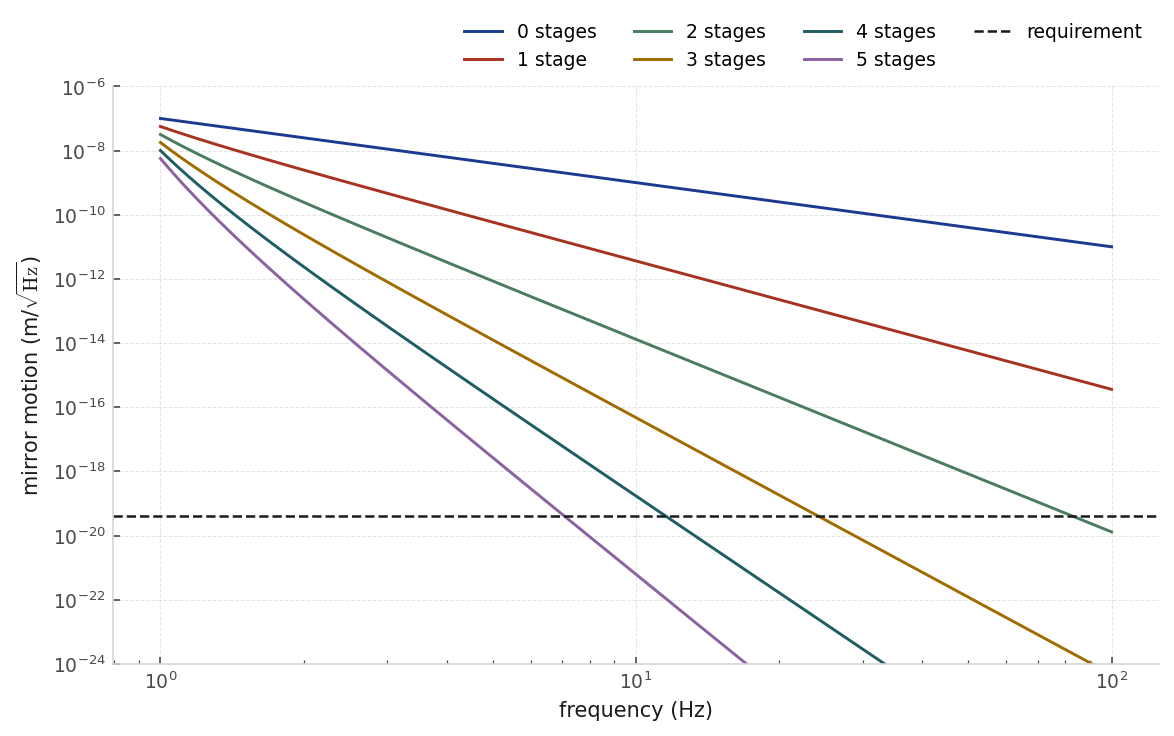

4 stages meet the requirement above 11.6 Hz


In [20]:
# change these: the chain
N = 4             # number of stages (pendulums one under the other)
m = 40.0          # mass of the mirror (kg); it does not enter the isolation
ell = 0.69        # length of each pendulum (m): f_p = sqrt(g / ell) / 2 pi
phi_loss = 1e-3   # loss angle of each stage (no unit): plays the role of 1 / Q

# the ground motion (m/sqrt(Hz)), an assumed model of a quiet site, and the requirement on the mirror
f = np.geomspace(1, 100, 2000)
ground = 1e-7 / f ** 2
required = 1e-23 * 4000                      # strain 1e-23 over a 4 km arm (m/sqrt(Hz))
print(f"f_p = {np.sqrt(G_EARTH / ell) / (2 * np.pi):.3f} Hz;"
      f" one stage divides the motion at 10 Hz by {1 / stage(10.0, m, ell, phi_loss):.0f}")

# the mirror motion after 0, 1, ..., N+1 stages: the ground times |G| to the power n
fig, ax = plt.subplots(figsize=(9, 5))
for n in range(N + 2):
    at10 = 1e-7 / 10.0 ** 2 * stage(10.0, m, ell, phi_loss) ** n
    print(f"{n} stages: {at10:.2e} m/rtHz at 10 Hz, {at10 / required:9.3g} times the requirement")
    ax.loglog(f, ground * stage(f, m, ell, phi_loss) ** n, lw=1.4, label=f'{n} stage' + ('s' if n != 1 else ''))
ax.axhline(required, color=P['INK'], lw=1.2, ls='--', label='requirement')
ax.set(xlabel='frequency (Hz)', ylabel=r'mirror motion (m/$\sqrt{\mathrm{Hz}}$)', ylim=(1e-24, 1e-6))
ax.legend(loc='lower right', bbox_to_anchor=(1.0, 1.0), ncol=4, frameon=False, fontsize=9)
plt.show()

# the lowest frequency above which N stages are under the requirement
meets = f[ground * stage(f, m, ell, phi_loss) ** N < required]
print(f"{N} stages meet the requirement above {meets[0]:.1f} Hz" if meets.size else "never met")

**What to change.** On the line `# change these`, in this order:
1. `N` from 1 to 6: how many stages meet the requirement at 10 Hz?
2. `m` (try 10 and 160 kg): does the isolation change?
3. `ell` (try 0.3, 1.0 and 1.5 m) with `N` = 4: how long must a stage be?

**What to look for.** Each stage divides the motion by $(f/f_{p})^{2}$ above its resonance, so the curves get steeper with $N$: the slope is $-(2 + 2N)$ with the ground. Four stages are still a little short at 10 Hz. Five are enough.

**Question.** Change the mass, then the length, then $N$. Why does the mass not change the isolation? How many stages of 0.69 m meet the requirement at 10 Hz? How long must four stages be?

<details>
<summary>Solution</summary>

With $\ell = 0.69$ m, $f_{p} = 0.600$ Hz and one stage divides the motion at 10 Hz by 277. The mirror motion at 10 Hz is $1.0\times10^{-9}$, $3.6\times10^{-12}$, $1.3\times10^{-14}$, $4.7\times10^{-17}$, $1.7\times10^{-19}$ and $6.2\times10^{-22}\ \mathrm{m}/\sqrt{\mathrm{Hz}}$ for 0 to 5 stages. Four stages are a factor $4.27$ short and meet the requirement only above $11.6$ Hz; five stages are enough.

The spring constant of a pendulum, $k = m g_{\oplus}/\ell$, grows with the mass as the inertia does, so $f_{p}^{2} = g_{\oplus}/(4\pi^{2}\ell)$ does not depend on $m$. Only the length sets the isolation of one stage, $(f_{p}/f)^{2} \propto 1/\ell$. Four stages gain $\ell^{4}$, so a factor $4.3$ needs $\ell$ larger by $4.3^{1/4} = 1.44$: about 1 m per stage. The exponent of the slope is a count of pendulums. Open `H04`, find the seismic term of the noise budget and account for its exponent 10.

</details>


## What to hand in

The answer to the question of each task, in two or three sentences, with the parameters you changed and what you saw:

1. **A · The transfer function.** The values of $|G|$ and $\phi$ below, at and above $f_{0}$. Which two numbers fix the curve.
2. **B · Any input.** Why one product gives the output for any input. What would break the superposition.
3. **C · The resonance.** Where the largest amplitude, the largest power and the phase of $-90^{\circ}$ lie. What sets the height and the width of the peak and why $\tau_{0}\Delta\omega = 2$.
4. **D · At the resonance and away from it.** What a bar gains at its resonance and what it pays. Why a high $Q$ keeps a violin mode in a narrow line. Which $f_{0}$ and $Q$ isolate a mirror and what the mirror does far below $f_{0}$.
5. **E · Several pendulums.** How many stages meet the requirement and how long four stages must be. Why only the length of a pendulum matters.

> **Where this goes next**
>
> You have found the transfer function of the oscillator and used it for any input. You have seen what a resonance is and what it means to work at it and away from it. Below the natural frequency the mass follows the input. At the resonance it amplifies, in a narrow band. Far above it isolates. Every stage of a chain isolates again. A detector uses all three and all of it rests on linearity.

## Software

`numpy` throughout. `solve_ivp` integrates the equation of the oscillator and `np.fft` gives the product $G\,X_{\mathrm{in}}$. The oscillator, the loss angle and the pendulum isolation are treated as in (Saulson 2017). The transforms follow (Oppenheim et al. 1997). The resonant bars are described in (Allen and others 2000).

**References**

- Saulson (2017). *Fundamentals of Interferometric Gravitational Wave Detectors*.
- Oppenheim et al. (1997). *Signals and Systems*.
- Allen and others (2000). *First Search for Gravitational Wave Bursts with a Network of Detectors*.